In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

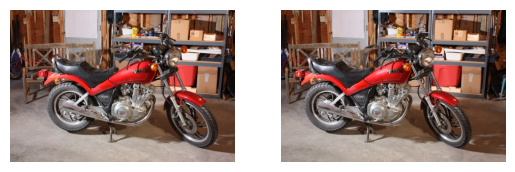

In [99]:
# Read the two images
img1 = mpimg.imread('im0.png')
img2 = mpimg.imread('im1.png')

# Example: Display them side-by-side using subplots
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img1)
ax[0].axis('off') # Hide axes ticks

ax[1].imshow(img2)
ax[1].axis('off')

plt.show()

In [3]:
print(type(img1))  # Output: <class 'numpy.ndarray'>

# Check the dimensions (Height x Width x Channels)
print(img1.shape)
print(img2.shape)

<class 'numpy.ndarray'>
(2000, 2964, 3)
(2000, 2964, 3)


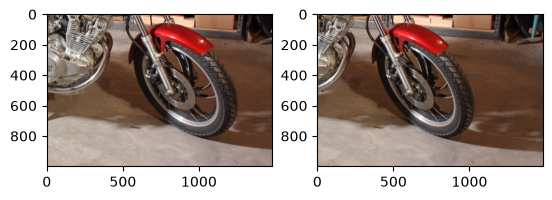

In [78]:
smimg1 = img1[1000:2000,1482:2964]
smimg2 = img2[1000:2000,1482:2964]


fig, ax = plt.subplots(1, 2)
ax[0].imshow(smimg1)
ax[1].imshow(smimg2)
plt.show()

In [11]:
# MAX_X = smimg1.shape[1]
# MAX_Y = smimg1.shape[0]

# print(MAX_X, MAX_Y)

def construct_square(img, x, y, sqsize):
    square = img[y-sqsize:y+sqsize,x-sqsize:x+sqsize]
    return square

def compare_squares(l_square, r_square):
    diff = l_square - r_square
    matching_cost = np.sum(np.abs(diff))
    return matching_cost

def find_best_disparity(l_img, r_img, x, y, sqsize):
    base_l_square = construct_square(l_img, x, y, sqsize)

    max_disparity = x - (0 + sqsize) # disaprity can be all the way up to the edge

    min_matching_cost = -1
    best_disparity = -1
    for i in range(0, max_disparity):
        r_square = construct_square(r_img, x - i, y, sqsize)

        matching_cost = compare_squares(base_l_square, r_square)
        if (matching_cost < min_matching_cost) or (i == 0):
            min_matching_cost = matching_cost
            best_disparity = i

    return best_disparity

In [22]:
def get_full_disparity_map(l_img, r_img, sqsize):
    h, w = l_img.shape[:2]
    disparity_map = np.zeros((h, w))

    for y in range(sqsize, h-sqsize):
        for x in range(sqsize, w-sqsize):
            disparity_map[y, x] = find_best_disparity(l_img, r_img, x, y, sqsize)
        print("Progress: ", y/h*100)
    return disparity_map

In [23]:
dp_map = get_full_disparity_map(smimg1, smimg2, 30)

Progress:  3.0
Progress:  3.1
Progress:  3.2
Progress:  3.3000000000000003
Progress:  3.4000000000000004
Progress:  3.5000000000000004
Progress:  3.5999999999999996
Progress:  3.6999999999999997
Progress:  3.8
Progress:  3.9
Progress:  4.0
Progress:  4.1000000000000005
Progress:  4.2
Progress:  4.3
Progress:  4.3999999999999995
Progress:  4.5
Progress:  4.6
Progress:  4.7
Progress:  4.8
Progress:  4.9
Progress:  5.0
Progress:  5.1
Progress:  5.2
Progress:  5.3
Progress:  5.4
Progress:  5.5
Progress:  5.6000000000000005
Progress:  5.7
Progress:  5.800000000000001
Progress:  5.8999999999999995
Progress:  6.0
Progress:  6.1
Progress:  6.2
Progress:  6.3
Progress:  6.4
Progress:  6.5
Progress:  6.6000000000000005
Progress:  6.7
Progress:  6.800000000000001
Progress:  6.9
Progress:  7.000000000000001
Progress:  7.1
Progress:  7.199999999999999
Progress:  7.3
Progress:  7.3999999999999995
Progress:  7.5
Progress:  7.6
Progress:  7.7
Progress:  7.8
Progress:  7.9
Progress:  8.0
Progress:  8.1

In [27]:
print(dp_map)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [79]:
from scipy.ndimage import uniform_filter

def get_full_disparity_map_fast(l_img, r_img, sqsize, max_disparity):
    window_size = sqsize * 2
    h, w = l_img.shape[:2]
    cost_volume = np.zeros((h, w, max_disparity))

    for d in range(max_disparity):
        if d == 0:
            shifted_r_img = r_img
        else:
            shifted_r_img = np.zeros_like(r_img)
            shifted_r_img[:, d:] = r_img[:, :-d]
            
        abs_diff = np.sum(np.abs(l_img - shifted_r_img), axis=2)
        cost_volume[:, :, d] = uniform_filter(abs_diff, size=window_size)
        
        print(f"\rProgress: {(d / max_disparity) * 100:.1f}%", end="", flush=True)


    disparity_map = np.argmin(cost_volume, axis=2)
    return disparity_map

In [31]:
def plot_disparity(dp_map, name):
    plt.imshow(dp_map, cmap='turbo')
    plt.colorbar(label='Disparity (pixels)')
    plt.title(f'Disparity Map - {name}')
    plt.show()

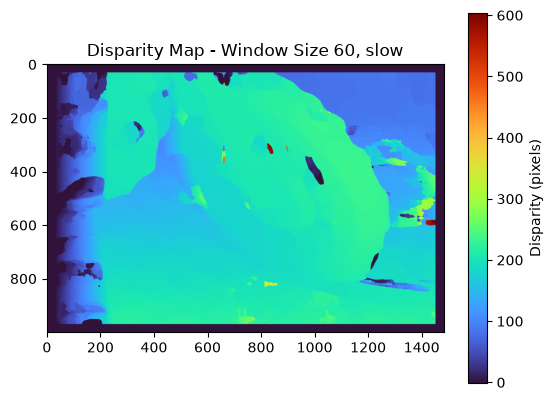

In [33]:
dp_map
plot_disparity(dp_map, 'Window Size 60, slow')

Progress: 99.8%

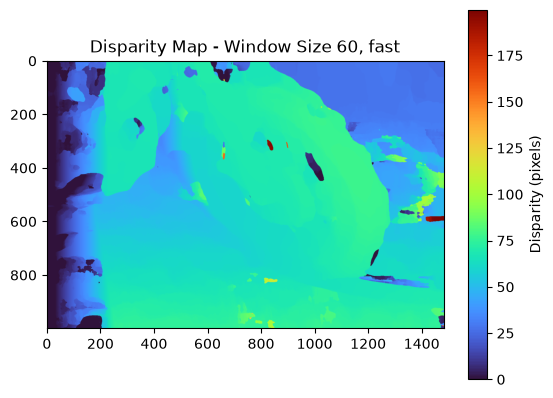

In [98]:
dp_map_fast_60 = get_full_disparity_map_fast(smimg1, smimg2, 30, 600)
plot_disparity(dp_map_fast_60/3, 'Window Size 60, fast')

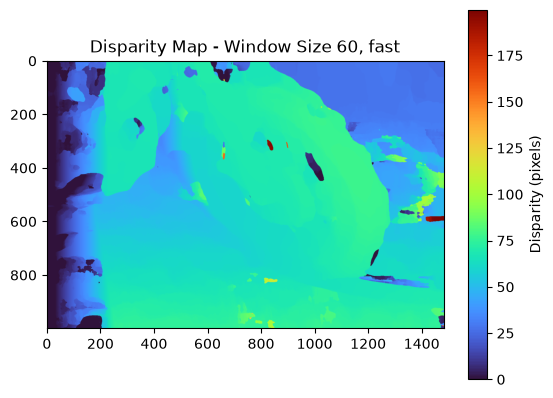

In [81]:
plot_disparity(dp_map_fast_60/3, 'Window Size 60, fast')

In [49]:
dp_map_fast_60_128 = get_full_disparity_map_fast(smimg1, smimg2, 30, 128)

Progress: 99.2%

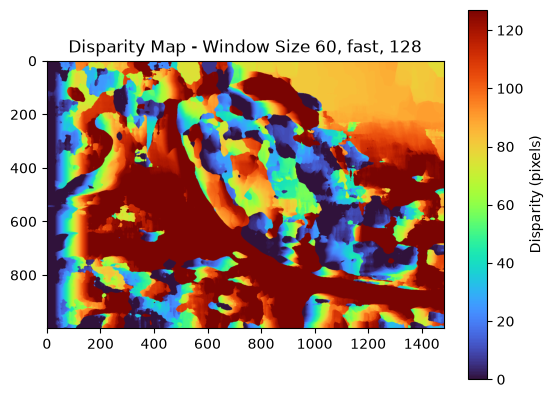

In [50]:
plot_disparity(dp_map_fast_60_128, 'Window Size 60, fast, 128')

In [51]:
dp_map_fast_60_256 = get_full_disparity_map_fast(smimg1, smimg2, 30, 256)

Progress: 99.6%

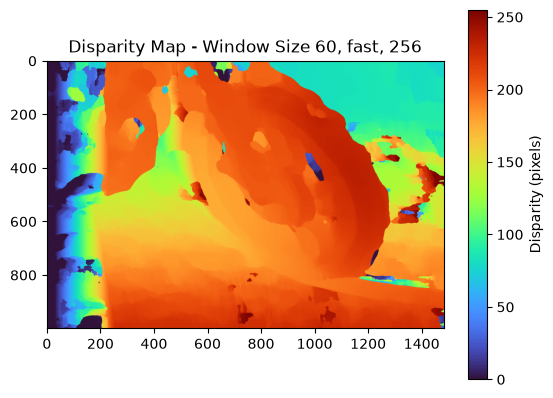

In [53]:
plot_disparity(dp_map_fast_60_256, 'Window Size 60, fast, 256')

In [55]:
dp_map_fast_60_512 = get_full_disparity_map_fast(smimg1, smimg2, 30, 512)

Progress: 99.8%

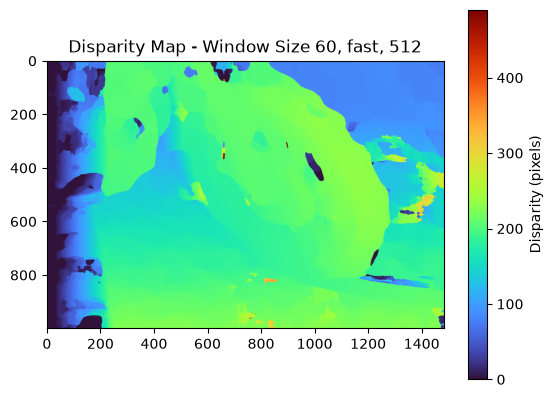

In [56]:
plot_disparity(dp_map_fast_60_512, 'Window Size 60, fast, 512')

In [57]:
dp_map_fast_100_256 = get_full_disparity_map_fast(smimg1, smimg2, 50, 256)

Progress: 99.6%

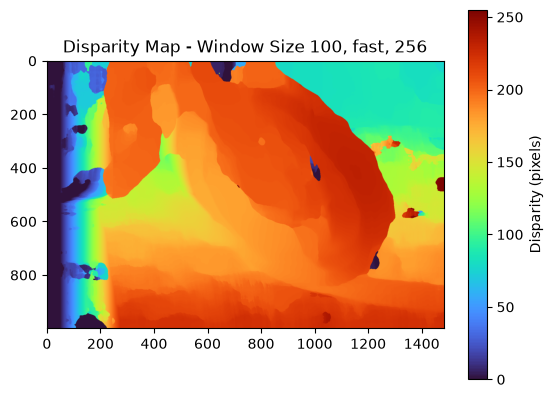

In [58]:
plot_disparity(dp_map_fast_100_256, 'Window Size 100, fast, 256')

In [59]:
dp_map_fast_20_256 = get_full_disparity_map_fast(smimg1, smimg2, 10, 256)

Progress: 99.6%

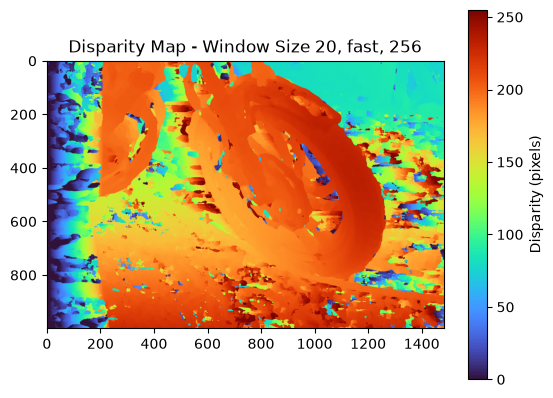

In [60]:
plot_disparity(dp_map_fast_20_256, 'Window Size 20, fast, 256')

In [100]:
dp_map_fast_11_256 = get_full_disparity_map_fast(smimg1, smimg2, 5, 256)

Progress: 99.6%

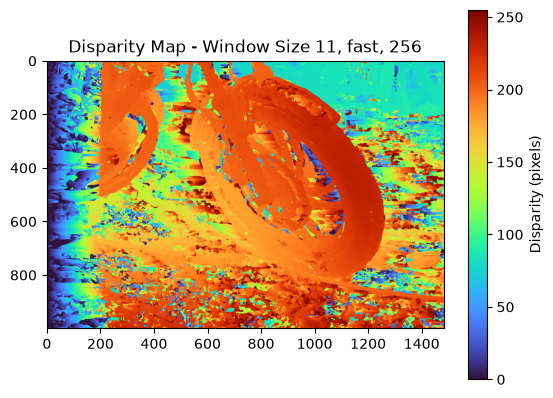

In [101]:
plot_disparity(dp_map_fast_11_256, 'Window Size 11, fast, 256')

In [ ]:
%pip install opencv-python

In [67]:
import cv2

def cv_block_match_disparity(l_img, r_img, window, max_disparity):
    gray_l = cv2.cvtColor(l_img, cv2.COLOR_RGB2GRAY)
    gray_r = cv2.cvtColor(r_img, cv2.COLOR_RGB2GRAY)

    gray_l = (gray_l * 255).astype(np.uint8)
    gray_r = (gray_r * 255).astype(np.uint8)
    
    stereo_bm = cv2.StereoBM_create(numDisparities=max_disparity, blockSize=window)
    raw_disp_bm = stereo_bm.compute(gray_l, gray_r)
    disparity_bm = raw_disp_bm.astype(np.float32) / 16.0

    return disparity_bm

In [84]:
dp_map_cv_61_128 = cv_block_match_disparity(smimg1, smimg2, 61, 128)

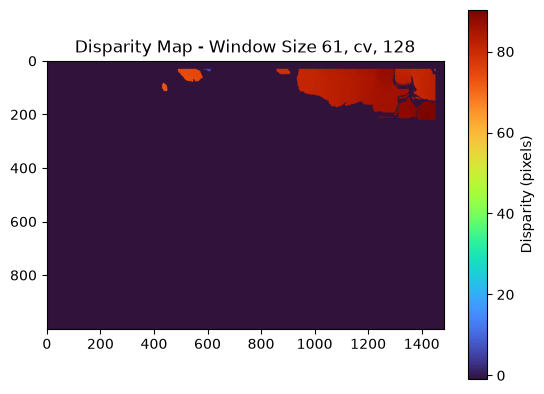

In [86]:
plot_disparity(dp_map_cv_61_128, 'Window Size 61, cv, 128')

In [92]:
dp_map_cv_61_256 = cv_block_match_disparity(smimg1, smimg2, 61, 256)

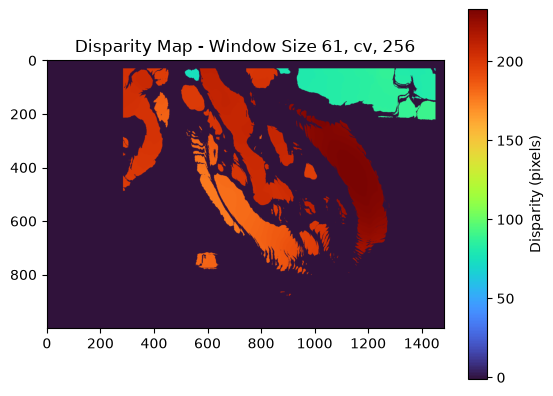

In [93]:
plot_disparity(dp_map_cv_61_256, 'Window Size 61, cv, 256')

In [95]:
dp_map_cv_11_256 = cv_block_match_disparity(smimg1, smimg2, 11, 256)

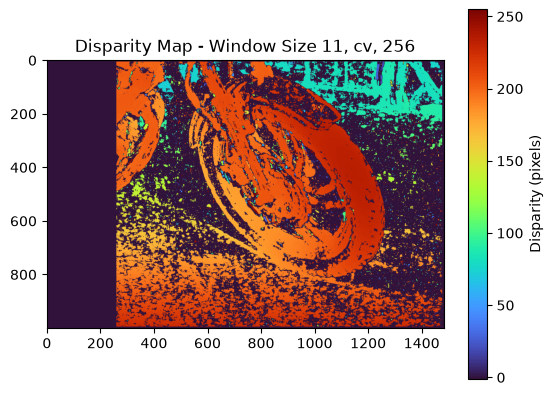

In [96]:
plot_disparity(dp_map_cv_11_256, 'Window Size 11, cv, 256')

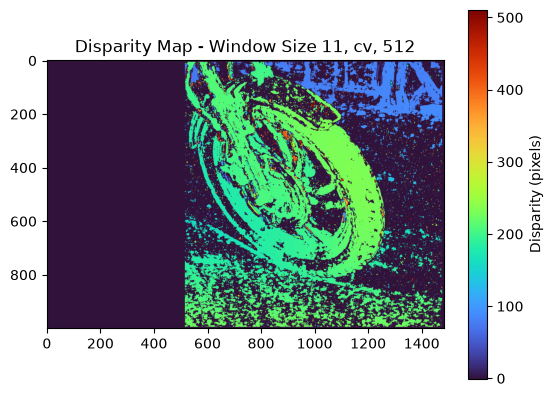

In [97]:
dp_map_cv_11_512 = cv_block_match_disparity(smimg1, smimg2, 11, 512)
plot_disparity(dp_map_cv_11_512, 'Window Size 11, cv, 512')